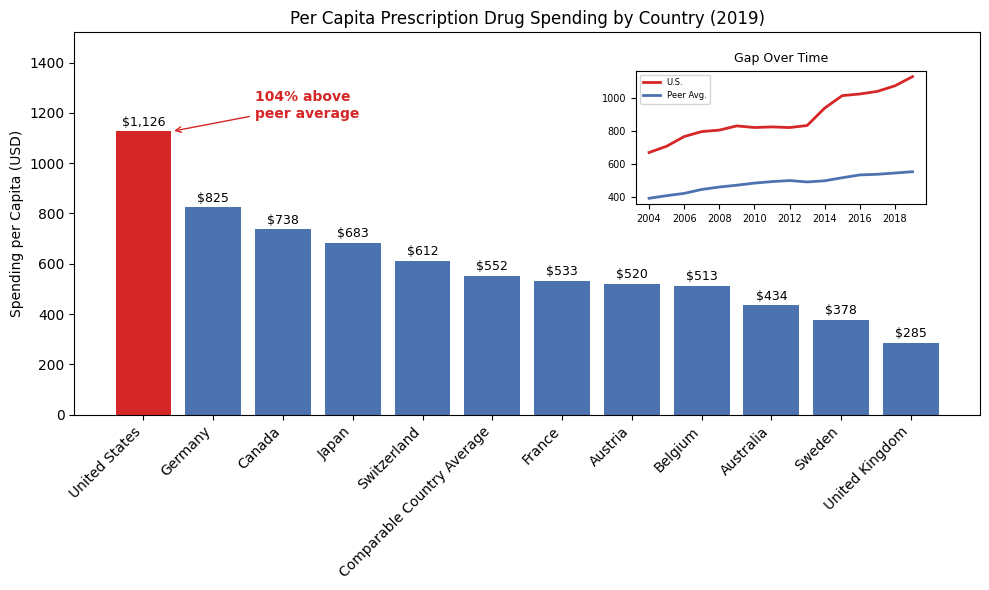

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt


df = pd.read_csv("data-x2xEg.csv")

df = df.rename(columns={"X.1": "Year"})


country_cols = [c for c in df.columns if c != "Year"]
df[country_cols] = df[country_cols].replace("..", pd.NA)
df[country_cols] = df[country_cols].apply(pd.to_numeric)


latest_year = df["Year"].max()
latest = df[df["Year"] == latest_year].drop(columns="Year").T
latest.columns = ["Per Capita Spending (USD)"]
latest = latest.dropna().sort_values("Per Capita Spending (USD)", ascending=False)

colors = ["#d62728" if country == "United States" else "#4C72B0" for country in latest.index]


peer_avg_latest = latest.loc["Comparable Country Average", "Per Capita Spending (USD)"]
us_latest = latest.loc["United States", "Per Capita Spending (USD)"]
pct_above = (us_latest / peer_avg_latest - 1) * 100

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.bar(latest.index, latest["Per Capita Spending (USD)"], color=colors)

ax.set_title(f"Per Capita Prescription Drug Spending by Country ({latest_year})")
ax.set_ylabel("Spending per Capita (USD)")
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")


ax.set_ylim(0, latest["Per Capita Spending (USD)"].max() * 1.35)


for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, height + 10, f"${height:,.0f}",
             ha="center", va="bottom", fontsize=9)


us_bar = bars[list(latest.index).index("United States")]
ax.annotate(f"{pct_above:.0f}% above\npeer average",
            xy=(us_bar.get_x() + us_bar.get_width(), us_bar.get_height()),
            xytext=(60, 10), textcoords="offset points",
            ha="left", fontsize=10, fontweight="bold", color="#d62728",
            arrowprops=dict(arrowstyle="->", color="#d62728"))


inset = ax.inset_axes([0.62, 0.55, 0.32, 0.35])
inset.plot(df["Year"], df["United States"], color="#d62728", linewidth=2, label="U.S.")
inset.plot(df["Year"], df["Comparable Country Average"], color="#4C72B0", linewidth=2, label="Peer Avg.")
inset.set_title("Gap Over Time", fontsize=9)
inset.tick_params(labelsize=7)
inset.legend(fontsize=6, loc="upper left")

plt.tight_layout()
plt.savefig("per_capita_drug_spending.png", dpi=300)
plt.show()

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

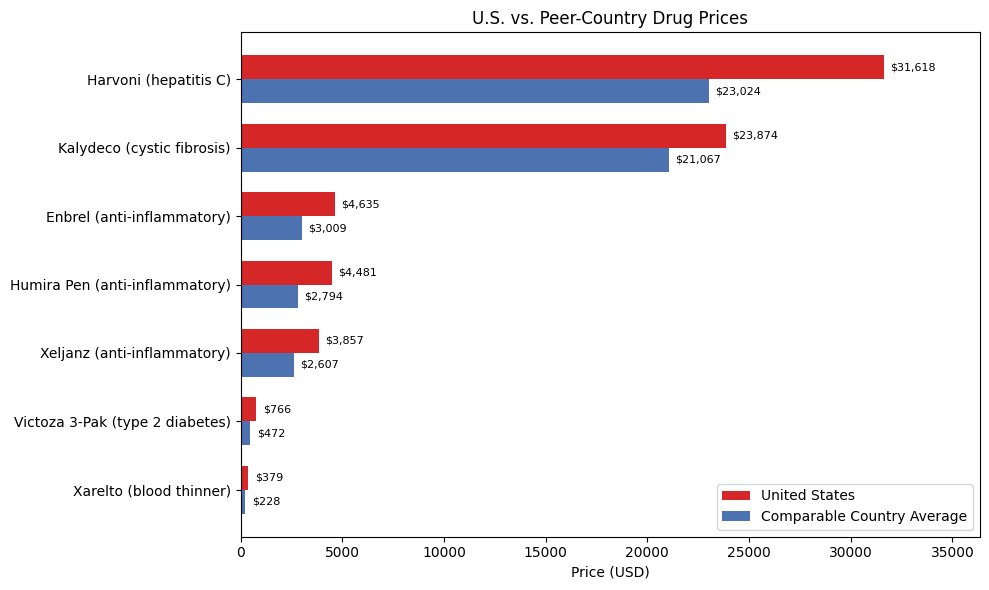

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import re


df = pd.read_csv("data-Prj8d.csv")

df["Drug"] = df["Drug"].apply(lambda x: re.sub(r"<.*?>", "", x))

def brand_and_condition(name):
    brand_part, condition = name.split(" - ")
    brand = brand_part.split(" (")[0].strip()
    return f"{brand} ({condition.strip()})"

df["Drug"] = df["Drug"].apply(brand_and_condition)


df = df.sort_values("United States", ascending=True).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(10, 6))

bar_height = 0.35
y = range(len(df))


us_bars = ax.barh([i + bar_height / 2 for i in y], df["United States"],
                    height=bar_height, color="#d62728", label="United States")
peer_bars = ax.barh([i - bar_height / 2 for i in y], df["Comparable Country Average"],
                      height=bar_height, color="#4C72B0", label="Comparable Country Average")

ax.set_yticks(list(y))
ax.set_yticklabels(df["Drug"])
ax.set_xlabel("Price (USD)")
ax.set_title("U.S. vs. Peer-Country Drug Prices")
ax.legend(loc="lower right")

ax.set_xlim(0, df["United States"].max() * 1.15)


for bar in list(us_bars) + list(peer_bars):
    width = bar.get_width()
    ax.text(width + df["United States"].max() * 0.01, bar.get_y() + bar.get_height() / 2,
             f"${width:,.0f}", ha="left", va="center", fontsize=8)

plt.tight_layout()
plt.savefig("us_vs_peer_drug_prices.png", dpi=300)
plt.show()

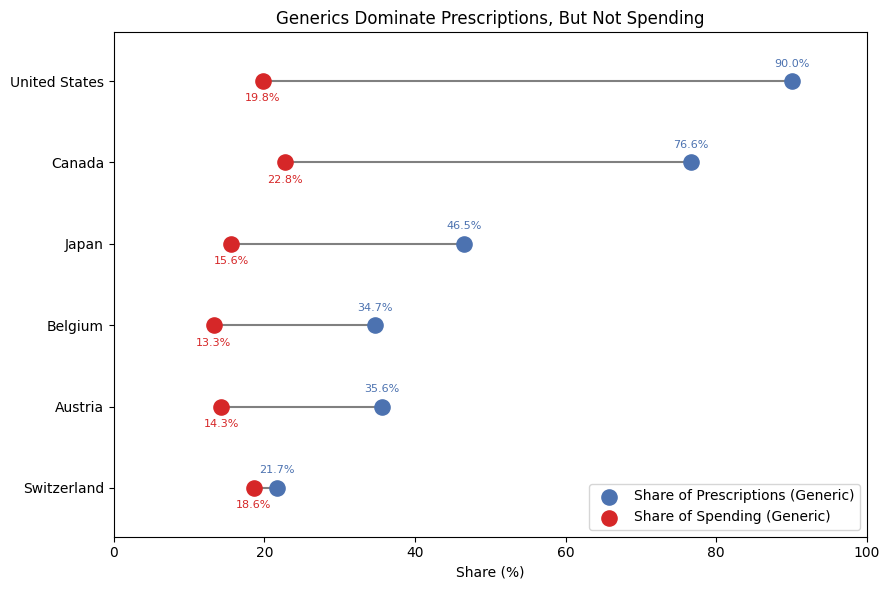

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt


df = pd.read_csv("data-Y1WUW.csv")


df["Share of prescription drug spending"] = pd.to_numeric(
    df["Share of prescription drug spending"], errors="coerce"
)
df = df.dropna(subset=["Share of prescription drug spending"])

df["gap"] = df["Share of dispensed prescriptions"] - df["Share of prescription drug spending"]
df = df.sort_values("gap", ascending=True).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(9, 6))
y = range(len(df))


for i, row in df.iterrows():
    ax.plot([row["Share of prescription drug spending"], row["Share of dispensed prescriptions"]],
            [i, i], color="gray", linewidth=1.5, zorder=1)


rx_color = "#4C72B0"
spend_color = "#d62728"
ax.scatter(df["Share of dispensed prescriptions"], y, color=rx_color, s=120, zorder=2,
           label="Share of Prescriptions (Generic)")
ax.scatter(df["Share of prescription drug spending"], y, color=spend_color, s=120, zorder=2,
           label="Share of Spending (Generic)")

ax.set_yticks(list(y))
ax.set_yticklabels(df["Country"])
ax.set_xlabel("Share (%)")
ax.set_xlim(0, 100)
ax.set_ylim(-0.6, len(df) - 1 + 0.6)
ax.set_title("Generics Dominate Prescriptions, But Not Spending")
ax.legend(loc="lower right")

for i, row in df.iterrows():
    ax.text(row["Share of dispensed prescriptions"], i + 0.18,
             f"{row['Share of dispensed prescriptions']:.1f}%", ha="center", fontsize=8, color=rx_color)
    ax.text(row["Share of prescription drug spending"], i - 0.25,
             f"{row['Share of prescription drug spending']:.1f}%", ha="center", fontsize=8, color=spend_color)

plt.tight_layout()
plt.savefig("generic_rx_vs_spending_dumbbell.png", dpi=300)
plt.show()